In [1]:
import polars as pl
import matplotlib.pyplot as plt

In [ ]:
import os
os.getcwd()

In [3]:
import analyze_metrics as am

In [ ]:
import importlib
importlib.reload(am)

## Run functions to build metrics

In [5]:
am.price_trends()

Building price trend tables...
  1,410,573 usable (arm's-length) sales going into these tables.
  -> data\processed\metrics/price_trend_citywide_monthly.parquet (1,380 rows)
  -> data\processed\metrics/price_trend_by_neighborhood_annual.parquet (5,843 rows)
  -> data\processed\metrics/price_trend_by_building_class_annual.parquet (954 rows)
  -> data\processed\metrics/price_trend_by_tax_class_annual.parquet (83 rows)


In [34]:
am.turnover_metrics()

Building turnover rate tables...
  -> data\processed\metrics/turnover_borough_annual.parquet (115 rows)
  -> data\processed\metrics/turnover_neighborhood_approx_annual.parquet (5,818 rows) -- APPROXIMATE, see comment in the code


In [7]:
am.sales_activity()

Building sales volume and holding period tables...
  -> data\processed\metrics/sales_volume_by_building_class.parquet (954 rows)
  -> data\processed\metrics/holding_periods_by_building_class.parquet (143 rows)


In [8]:
am.class_transitions()

Building class transition tables...
  -> data\processed\metrics/building_class_transitions.parquet (2,871 distinct transition pairs, 41,302 properties involved)
  -> data\processed\metrics/tax_class_transitions.parquet (28 distinct transition pairs, 124,726 properties involved)


In [9]:
am.assessment_equity()

Building assessment equity (ratio study) tables...
  111,321 sales have a usable valuation match to compute a ratio from.
  trimmed 38,956 sales with a ratio outside the 0.1-5.0 range (not representative for a ratio study).
  -> data\processed\metrics/assessment_equity.parquet (114 rows)


## Read parquet results and visualize

In [10]:
# citywide price trends by month
citywide = pl.read_parquet("data/processed/metrics/price_trend_citywide_monthly.parquet")
print(citywide.sort(["borough", "sale_year", "sale_month"]).head(20))

shape: (20, 7)
┌─────────┬───────────┬────────────┬──────────────┬───────────┬────────────┬────────────┐
│ borough ┆ sale_year ┆ sale_month ┆ median_price ┆ p25_price ┆ p75_price  ┆ sale_count │
│ ---     ┆ ---       ┆ ---        ┆ ---          ┆ ---       ┆ ---        ┆ ---        │
│ str     ┆ i32       ┆ i8         ┆ f64          ┆ f64       ┆ f64        ┆ u32        │
╞═════════╪═══════════╪════════════╪══════════════╪═══════════╪════════════╪════════════╡
│ 1       ┆ 2003      ┆ 1          ┆ 440000.0     ┆ 276000.0  ┆ 800000.0   ┆ 1342       │
│ 1       ┆ 2003      ┆ 2          ┆ 376727.5     ┆ 253399.0  ┆ 523890.0   ┆ 1908       │
│ 1       ┆ 2003      ┆ 3          ┆ 444500.0     ┆ 267500.0  ┆ 840056.0   ┆ 1262       │
│ 1       ┆ 2003      ┆ 4          ┆ 475000.0     ┆ 285000.0  ┆ 945656.0   ┆ 1363       │
│ 1       ┆ 2003      ┆ 5          ┆ 442856.0     ┆ 272000.0  ┆ 865000.0   ┆ 1488       │
│ …       ┆ …         ┆ …          ┆ …            ┆ …         ┆ …          ┆ …       

In [12]:
# Neighborhood price trends annual
neighborhoods = pl.read_parquet("data/processed/metrics/price_trend_by_neighborhood_annual.parquet")
print(neighborhoods.sort("sale_year", descending=True).head(20))

shape: (20, 7)
┌─────────┬───────────────┬───────────┬──────────────┬───────────┬───────────┬────────────┐
│ borough ┆ neighborhood  ┆ sale_year ┆ median_price ┆ p25_price ┆ p75_price ┆ sale_count │
│ ---     ┆ ---           ┆ ---       ┆ ---          ┆ ---       ┆ ---       ┆ ---        │
│ str     ┆ str           ┆ i32       ┆ f64          ┆ f64       ┆ f64       ┆ u32        │
╞═════════╪═══════════════╪═══════════╪══════════════╪═══════════╪═══════════╪════════════╡
│ 1       ┆ ALPHABET CITY ┆ 2025      ┆ 746889.5     ┆ 500000.0  ┆ 1.2e6     ┆ 84         │
│ 1       ┆ CHELSEA       ┆ 2025      ┆ 1.35e6       ┆ 680000.0  ┆ 2.86e6    ┆ 741        │
│ 1       ┆ CHINATOWN     ┆ 2025      ┆ 1.827225e6   ┆ 880000.0  ┆ 3.1625e6  ┆ 48         │
│ 1       ┆ CIVIC CENTER  ┆ 2025      ┆ 3.05e6       ┆ 2e6       ┆ 4.725e6   ┆ 139        │
│ 1       ┆ CLINTON       ┆ 2025      ┆ 950000.0     ┆ 620000.0  ┆ 1.55e6    ┆ 225        │
│ …       ┆ …             ┆ …         ┆ …            ┆ …         

In [35]:
# Turnover rate by borough
turnover = pl.read_parquet("data/processed/metrics/turnover_borough_annual.parquet")
print(turnover.sort(["borough", "sale_year"]).head(20))

shape: (20, 5)
┌─────────┬───────────┬──────────────┬─────────────┬───────────────────┐
│ borough ┆ sale_year ┆ transactions ┆ total_units ┆ turnover_rate_pct │
│ ---     ┆ ---       ┆ ---          ┆ ---         ┆ ---               │
│ str     ┆ i32       ┆ u32          ┆ f64         ┆ f64               │
╞═════════╪═══════════╪══════════════╪═════════════╪═══════════════════╡
│ 1       ┆ 2003      ┆ 18422        ┆ 1.094463e6  ┆ 1.6832            │
│ 1       ┆ 2004      ┆ 21390        ┆ 1.094463e6  ┆ 1.954383          │
│ 1       ┆ 2005      ┆ 21580        ┆ 1.094463e6  ┆ 1.971743          │
│ 1       ┆ 2006      ┆ 22038        ┆ 1.094463e6  ┆ 2.01359           │
│ 1       ┆ 2007      ┆ 23179        ┆ 1.094463e6  ┆ 2.117842          │
│ …       ┆ …         ┆ …            ┆ …           ┆ …                 │
│ 1       ┆ 2018      ┆ 12844        ┆ 1.094463e6  ┆ 1.173544          │
│ 1       ┆ 2019      ┆ 13145        ┆ 1.094463e6  ┆ 1.201046          │
│ 1       ┆ 2020      ┆ 9077        

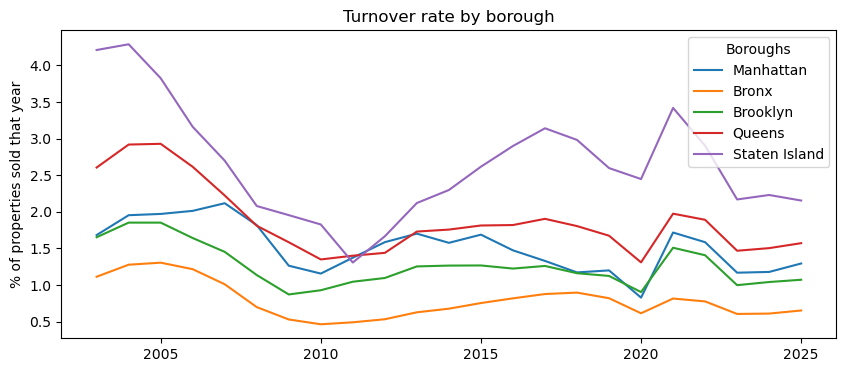

In [36]:
plt.figure(figsize=(10, 4))
for boro, label in [("1", "Manhattan"), ("2", "Bronx"), ("3", "Brooklyn"), ("4", "Queens"), ("5", "Staten Island")]:
    subset = turnover.filter(pl.col("borough") == boro).sort("sale_year")
    plt.plot(subset["sale_year"], subset["turnover_rate_pct"], label=label)
plt.title("Turnover rate by borough")
plt.ylabel("% of properties sold that year")
plt.legend(title="Boroughs")
plt.show()

In [15]:
# Building class transitions
transitions = pl.read_parquet("data/processed/metrics/building_class_transitions.parquet")
print(transitions.sort("count", descending=True).head(20))  # most common transitions first

shape: (20, 3)
┌────────────────────────────────┬────────────────────────┬───────┐
│ building_class_at_time_of_sale ┆ current_building_class ┆ count │
│ ---                            ┆ ---                    ┆ ---   │
│ str                            ┆ str                    ┆ u32   │
╞════════════════════════════════╪════════════════════════╪═══════╡
│ A1                             ┆ B3                     ┆ 1955  │
│ A2                             ┆ B3                     ┆ 1585  │
│ A2                             ┆ A1                     ┆ 1520  │
│ R4                             ┆ RM                     ┆ 1107  │
│ V0                             ┆ C0                     ┆ 1098  │
│ …                              ┆ …                      ┆ …     │
│ R2                             ┆ R4                     ┆ 356   │
│ B3                             ┆ C0                     ┆ 333   │
│ A1                             ┆ B1                     ┆ 326   │
│ A0                             

In [16]:
# building assessment equity
equity = pl.read_parquet("data/processed/metrics/assessment_equity.parquet")
print(equity.sort(["val_tax_class", "sale_year"]).head(20))

shape: (20, 8)
┌───────────────┬─────────┬───────────┬──────────────┬────────────┬───────────┬──────────┬─────────┐
│ val_tax_class ┆ borough ┆ sale_year ┆ median_ratio ┆ mean_ratio ┆ cod       ┆ prd      ┆ n_sales │
│ ---           ┆ ---     ┆ ---       ┆ ---          ┆ ---        ┆ ---       ┆ ---      ┆ ---     │
│ str           ┆ str     ┆ i32       ┆ f64          ┆ f64        ┆ f64       ┆ f64      ┆ u32     │
╞═══════════════╪═════════╪═══════════╪══════════════╪════════════╪═══════════╪══════════╪═════════╡
│ 1             ┆ 5       ┆ 2023      ┆ 0.928838     ┆ 1.003351   ┆ 21.520396 ┆ 1.071653 ┆ 3480    │
│ 1             ┆ 1       ┆ 2023      ┆ 1.192778     ┆ 1.268243   ┆ 37.298805 ┆ 1.281932 ┆ 177     │
│ 1             ┆ 2       ┆ 2023      ┆ 0.962002     ┆ 1.062914   ┆ 26.406134 ┆ 1.115343 ┆ 1969    │
│ 1             ┆ 3       ┆ 2023      ┆ 0.97931      ┆ 1.080221   ┆ 31.036987 ┆ 1.135336 ┆ 5207    │
│ 1             ┆ 4       ┆ 2023      ┆ 0.978313     ┆ 1.066907   ┆ 23.85108

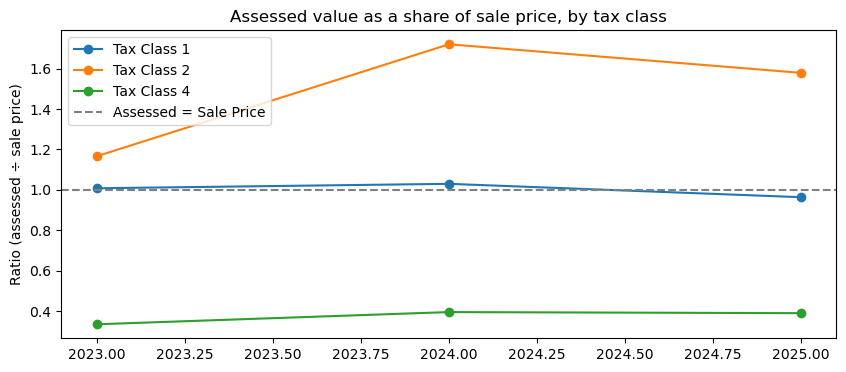

In [43]:
citywide_equity = (
    equity.group_by(["val_tax_class", "sale_year"])
    .agg(pl.col("median_ratio").mean().alias("avg_median_ratio"))  # rough citywide blend across boroughs
    .sort(["val_tax_class", "sale_year"])
)

plt.figure(figsize=(10, 4))
for tc in ["1", "2", "4"]:
    subset = citywide_equity.filter(pl.col("val_tax_class") == tc).sort("sale_year")
    plt.plot(subset["sale_year"], subset["avg_median_ratio"], marker="o", label=f"Tax Class {tc}")
plt.axhline(1.0, color="gray", linestyle="--", label="Assessed = Sale Price")
plt.title("Assessed value as a share of sale price, by tax class")
plt.ylabel("Ratio (assessed ÷ sale price)")
plt.legend()
plt.show()

## Plots

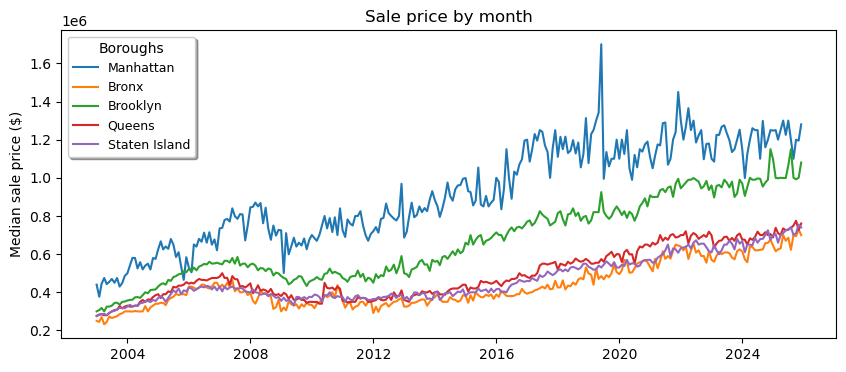

In [44]:

manhattan = citywide.filter(pl.col("borough") == "1").sort(["sale_year", "sale_month"])
bronx = citywide.filter(pl.col("borough") == "2").sort(["sale_year", "sale_month"])
brooklyn = citywide.filter(pl.col("borough") == "3").sort(["sale_year", "sale_month"])
queens = citywide.filter(pl.col("borough") == "4").sort(["sale_year", "sale_month"])
staten_island = citywide.filter(pl.col("borough") == "5").sort(["sale_year", "sale_month"])

# combine the separate year and month columns into one real date, so
# matplotlib can space the points out correctly along a timeline
# Add a proper date column
for df_name in ["manhattan", "bronx", "brooklyn", "queens", "staten_island"]:
    locals()[df_name] = locals()[df_name].with_columns(
        pl.date(pl.col("sale_year"), pl.col("sale_month"), 1).alias("month_date")
    )

plt.figure(figsize=(10, 4))
plt.plot(manhattan["month_date"], manhattan["median_price"], label = "Manhattan")
plt.plot(bronx["month_date"], bronx["median_price"], label = "Bronx")
plt.plot(brooklyn["month_date"], brooklyn["median_price"], label = "Brooklyn")
plt.plot(queens["month_date"], queens["median_price"], label = "Queens")
plt.plot(staten_island["month_date"], staten_island["median_price"], label = "Staten Island")
plt.title("Sale price by month")
plt.ylabel("Median sale price ($)")
plt.legend(
    loc='upper left',
    fontsize=9,
    frameon=True,
    shadow=True,
    title='Boroughs'
)
plt.show()

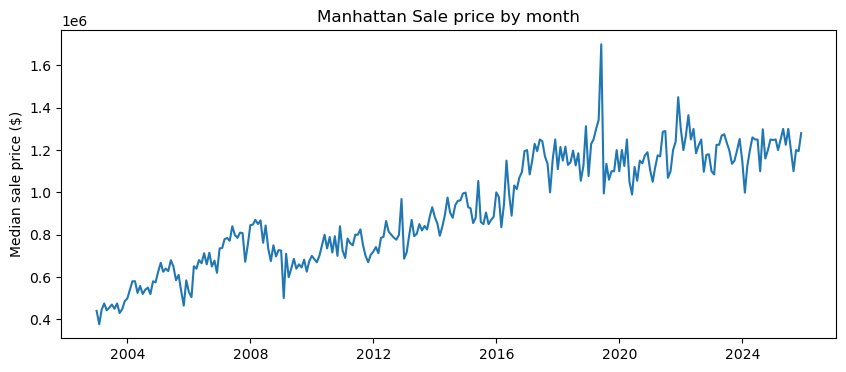

In [45]:
plt.figure(figsize=(10, 4))
plt.plot(manhattan["month_date"], manhattan["median_price"], label = "Manhattan")
plt.title("Manhattan Sale price by month")
plt.ylabel("Median sale price ($)")
plt.show()

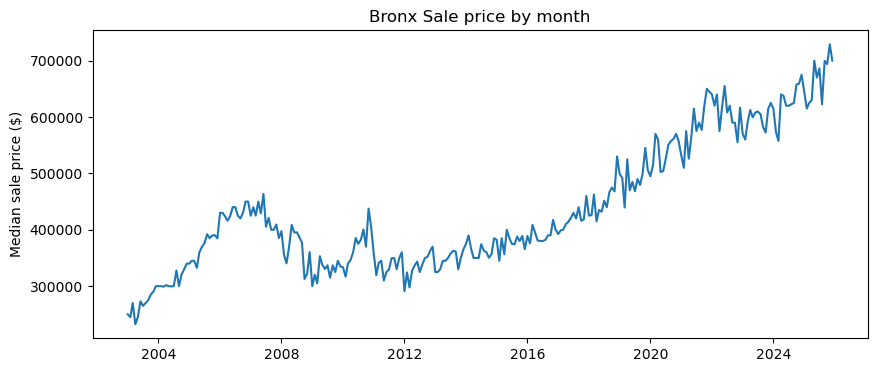

In [46]:
plt.figure(figsize=(10, 4))
plt.plot(bronx["month_date"], bronx["median_price"], label = "Bronx")
plt.title("Bronx Sale price by month")
plt.ylabel("Median sale price ($)")
plt.show()

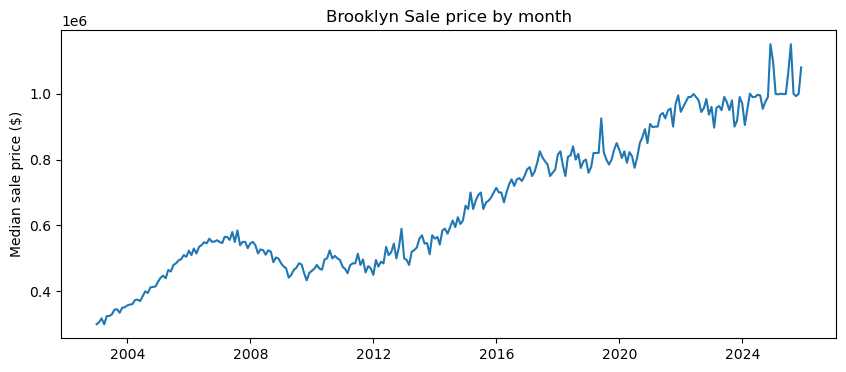

In [47]:
plt.figure(figsize=(10, 4))
plt.plot(brooklyn["month_date"], brooklyn["median_price"], label = "Brooklyn")
plt.title("Brooklyn Sale price by month")
plt.ylabel("Median sale price ($)")
plt.show()

In [40]:
sales = pl.read_parquet("data/processed/sales_enriched.parquet")
sales = sales.with_columns(sales["sale_price"].cast(pl.Float64, strict=False).alias("sale_price_num"))

near_million_sales = sales.filter(
    (pl.col("sale_price_num") >= 990_000) & (pl.col("sale_price_num") <= 1_010_000)
)
print(near_million_sales["sale_price_num"].value_counts().sort("count", descending=True).head(15))

shape: (15, 2)
┌────────────────┬───────┐
│ sale_price_num ┆ count │
│ ---            ┆ ---   │
│ f64            ┆ u32   │
╞════════════════╪═══════╡
│ 995000.0       ┆ 3634  │
│ 999000.0       ┆ 3538  │
│ 990000.0       ┆ 3160  │
│ 1e6            ┆ 1274  │
│ 9.99999e5      ┆ 1102  │
│ …              ┆ …     │
│ 1.01e6         ┆ 211   │
│ 997000.0       ┆ 154   │
│ 999990.0       ┆ 133   │
│ 996000.0       ┆ 100   │
│ 992794.0       ┆ 93    │
└────────────────┴───────┘


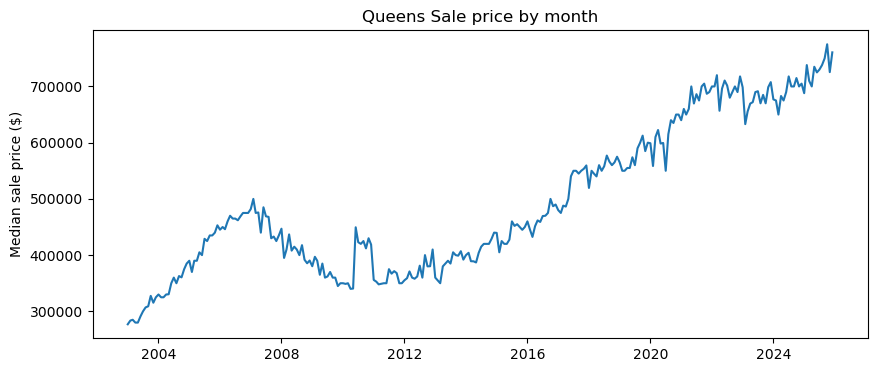

In [39]:
plt.figure(figsize=(10, 4))
plt.plot(queens["month_date"], queens["median_price"], label = "Queens")
plt.title("Queens Sale price by month")
plt.ylabel("Median sale price ($)")
plt.show()

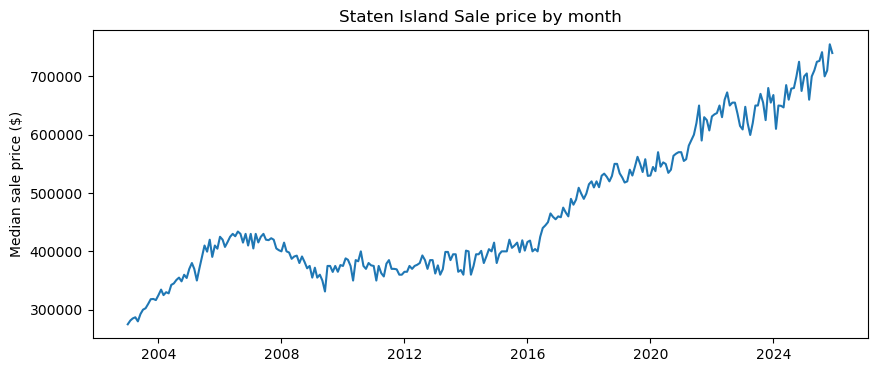

In [38]:
plt.figure(figsize=(10, 4))
plt.plot(staten_island["month_date"], staten_island["median_price"], label = "Staten Island")
plt.title("Staten Island Sale price by month")
plt.ylabel("Median sale price ($)")
plt.show()

In [42]:
with pl.Config(tbl_rows=-1):
    print(si_full.filter(pl.col("sale_year") == 2024).select(
        ["sale_year", "sale_month", "median_price", "sale_count"]
    ))

shape: (12, 4)
┌───────────┬────────────┬──────────────┬────────────┐
│ sale_year ┆ sale_month ┆ median_price ┆ sale_count │
│ ---       ┆ ---        ┆ ---          ┆ ---        │
│ i32       ┆ i8         ┆ f64          ┆ u32        │
╞═══════════╪════════════╪══════════════╪════════════╡
│ 2024      ┆ 1          ┆ 668000.0     ┆ 365        │
│ 2024      ┆ 2          ┆ 610000.0     ┆ 297        │
│ 2024      ┆ 3          ┆ 650000.0     ┆ 357        │
│ 2024      ┆ 4          ┆ 649500.0     ┆ 316        │
│ 2024      ┆ 5          ┆ 646750.0     ┆ 388        │
│ 2024      ┆ 6          ┆ 685000.0     ┆ 383        │
│ 2024      ┆ 7          ┆ 660000.0     ┆ 433        │
│ 2024      ┆ 8          ┆ 679000.0     ┆ 428        │
│ 2024      ┆ 9          ┆ 680000.0     ┆ 435        │
│ 2024      ┆ 10         ┆ 700000.0     ┆ 444        │
│ 2024      ┆ 11         ┆ 725000.0     ┆ 390        │
│ 2024      ┆ 12         ┆ 675000.0     ┆ 388        │
└───────────┴────────────┴──────────────┴─────────